# Practical 4: Matrix Addition (Pattern 2 + Multithreading)

### 1. Aim
To add three independent pairs of large 6500x6500 matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of 6500x6500 integer matrices.<br>2. Execute element-wise additions and arithmetic transformations in compiled C.<br>3. Sequential: add Pair 1 -> Pair 2 -> Pair 3 sequentially.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: launch 3 concurrent `threading.Thread` workers.<br>7. Compare wall-clock execution times and speedups.

### 3. Python Implementation


In [1]:
"""
Practical 4: Matrix Addition (Pattern 2 + Multithreading)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matrix_add_task(task):
    rows, cols, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 100, size=(rows, cols), dtype=np.int32)
    B = rng.integers(1, 100, size=(rows, cols), dtype=np.int32)
    # Computational element-wise matrix arithmetic in C (releases GIL)
    C = (A + B) * 3 + 1
    C = np.bitwise_xor(C, A) + np.bitwise_and(C, B)
    C = np.bitwise_xor(C * 41 + 23, C >> 3)
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matrix_add_task(task))

def thread_worker(task, results, idx):
    results[idx] = matrix_add_task(task)

def main():
    print("=" * 60)
    print("Practical 4: Matrix Addition (Pattern 2 + Multithreading)")
    print("=" * 60)
    ROWS, COLS = 6500, 6500
    tasks = [(ROWS, COLS, 101), (ROWS, COLS, 202), (ROWS, COLS, 303)]
    
    # 1. Sequential: Task 1 -> Task 2 -> Task 3
    t0 = time.perf_counter()
    r1 = matrix_add_task(tasks[0])
    r2 = matrix_add_task(tasks[1])
    r3 = matrix_add_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool: 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matrix_add_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process: 3 independent processes
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading: 3 threads
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Matrix Dimension: {ROWS}x{COLS} across 3 independent pairs.")
    print(f"Verification: Sequential={seq_res[0]} | Thread={thread_res[0]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 4: Matrix Addition (Pattern 2 + Multithreading)
Matrix Dimension: 6500x6500 across 3 independent pairs.
Verification: Sequential=9173 | Thread=9173
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.0689 seconds      1.00x
Pool         1.8391 seconds      1.67x
Process      1.9080 seconds      1.61x
Thread       1.3522 seconds      2.27x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


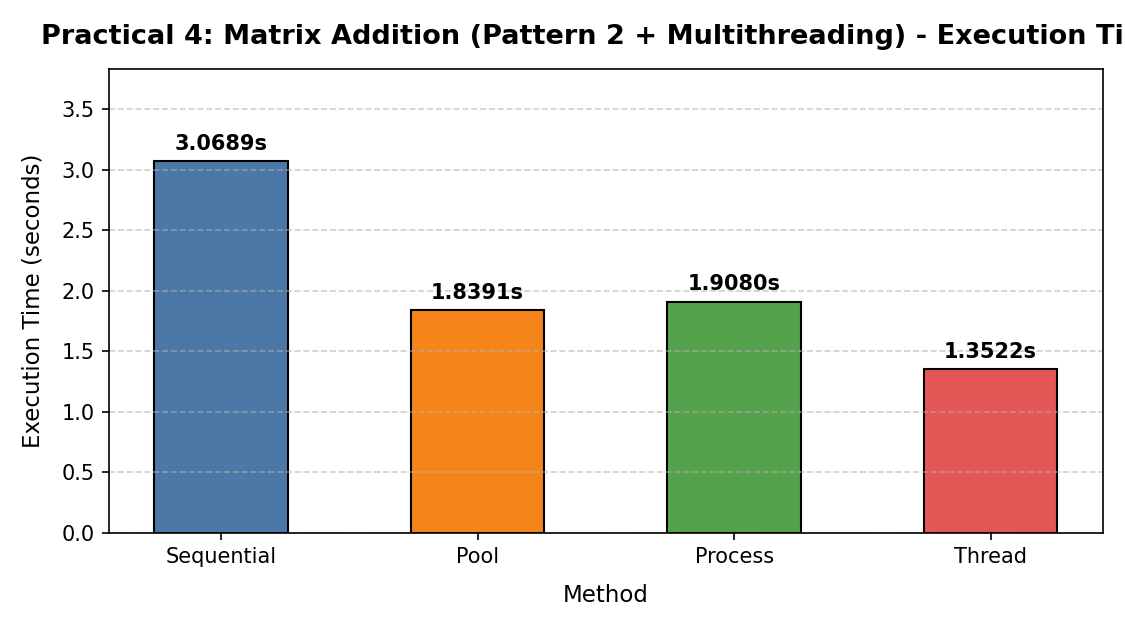

In [2]:
from IPython.display import Image, display
display(Image(filename='04_matrix_addition_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


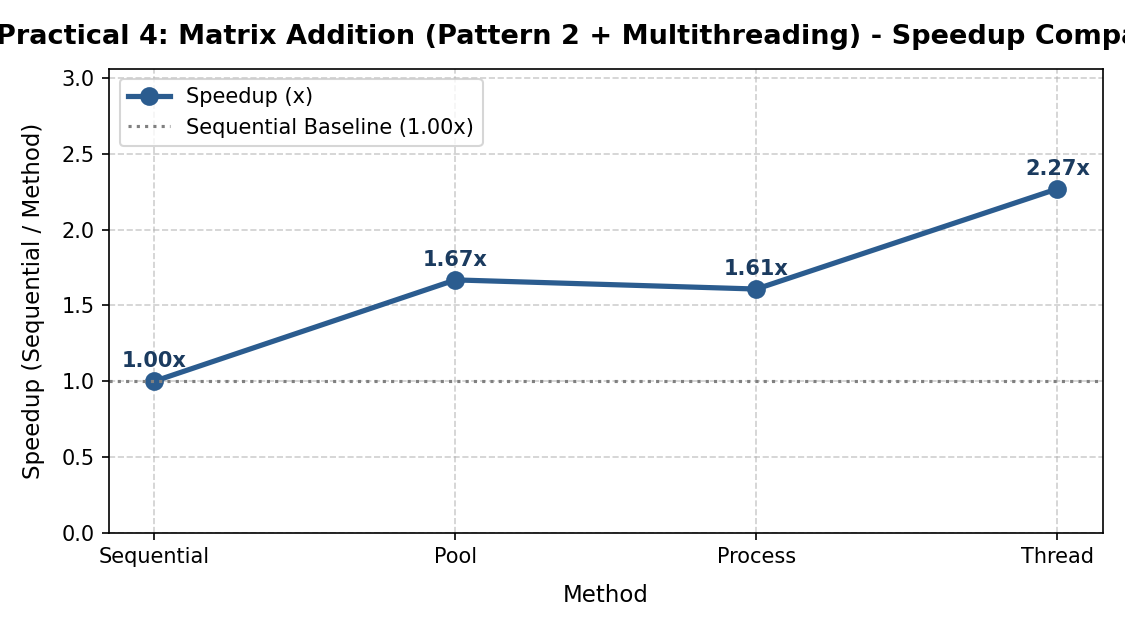

In [3]:
from IPython.display import Image, display
display(Image(filename='04_matrix_addition_speedup.png'))
